# 05 · "Not miss one" and the learning-curve gap

Recall (0.912) counts **pixels**. The clinical question counts **polyps**: in how many of the
120 test images does the U-Net hit the polyp at all, and how many polyps does it miss?
`src/hits.py` explains each count. Then the learning-curve question (Session 16): Dice on the
training images vs. validation vs. test, for the saved best epoch.
Loads the 6 U-Nets saved by notebook 03 (no training).

**Colab: Runtime → Change runtime type → T4 GPU, then Run all** (about 5 minutes; without a GPU about 15). Allow Google Drive when asked.

In [1]:
import os, sys, json
# On Colab: download our code from GitHub first (on a laptop it is already there).
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
# If started inside chandana/ or dinesh/, go up to the project folder, so data/ and src/ are found.
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")
# Data not there yet: download Kvasir-SEG (46 MB) and the authors' split lists.
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py
# Split not made yet: fingerprints, duplicate check, train/val/test lists.
if not os.path.exists("splits/train.txt"):
    !python scripts/make_split.py
# Let Python import our own modules from src/.
sys.path.insert(0, "src")

import numpy as np, matplotlib.pyplot as plt, torch
from pathlib import Path
from data import load_resized, read_split
from unet import UNet
from train import predict_probs
from hits import summarise, count_hits
from metrics import mean_scores
import baseline

if "google.colab" in sys.modules:
    from google.colab import drive
    # Google Drive keeps the trained models between Colab sessions.
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/kvasir_seg_runs")
else:
    RUNS = Path("checkpoints")
# Use the GPU if there is one (Colab T4), otherwise the CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"
# Every table and figure is saved in results/.
R = Path("results"); R.mkdir(exist_ok=True)

names = read_split("test")
pairs = [load_resized(n, 256) for n in names]
X = np.stack([p[0] for p in pairs]); Y = np.stack([p[1] for p in pairs])

# Load the 6 saved U-Nets and predict the 120 test images (no training).
preds = {}
for name in ("scratch", "pretrained"):
    for seed in (0, 1, 2):
        m = UNet(pretrained=False)
        # Load the weights saved by notebook 03 (no training here).
        m.load_state_dict(torch.load(RUNS / f"{name}_seed{seed}_epochs30.pt", map_location="cpu"))
        preds[(name, seed)] = predict_probs(m.to(device).eval(), X, device) > 0.5
preds[("baseline", 0)] = np.stack([baseline.predict(x, 11) for x in X])   # radius 11, chosen on validation
print("predictions ready")

Cloning into 'kvasir-seg-polyp-segmentation'...
remote: Enumerating objects: 181, done.
remote: Counting objects: 100% (181/181), done.
remote: Compressing objects: 100% (145/145), done.
remote: Total 181 (delta 84), reused 131 (delta 34), pack-reused 0 (from 0)
Receiving objects: 100% (181/181), 13.10 MiB | 27.20 MiB/s, done.
Resolving deltas: 100% (84/84), done.
/content/kvasir-seg-polyp-segmentation
Certificate problem on the Simula server; adding its missing certificate ...
Unzipping ...
Done: 1000 images, 1000 masks in data/Kvasir-SEG/
Mounted at /content/drive
predictions ready


## How many images and polyps are found? (mean ± std over the 3 seeds)

In [2]:
# Count per setting: images hit, polyps found, false alarms (src/hits.py).
counts = {k: summarise(p, Y) for k, p in preds.items()}
n_img, n_pol = counts[("baseline", 0)]["images"], counts[("baseline", 0)]["polyps"]
print(f"{n_img} test images with {n_pol} polyps (connected regions of the doctors' masks)")

# Format one table cell: mean ± std over the 3 seeds, and the percentage.
def cell(name, key, total):
    vals = [counts[(name, s)][key] for s in (0, 1, 2)] if name != "baseline" else [counts[("baseline", 0)][key]]
    m = np.mean(vals)
    sd = f" ± {np.std(vals, ddof=1):.1f}" if len(vals) > 1 else ""
    value = f"{m:.1f}{sd}" if len(vals) > 1 else f"{int(m)}"
    return f"{value} of {total} ({100 * m / total:.1f} %)"

lines = ["| Setting | images: polyp touched | images: IoU ≥ 0.5 | polyps found (any overlap) | polyps ≥ half covered | images with a false alarm |",
         "|---|---|---|---|---|---|"]
for name, label in (("baseline", "brightness threshold"), ("scratch", "U-Net scratch (3 seeds)"), ("pretrained", "U-Net pretrained (3 seeds)")):
    lines.append(f"| {label} | {cell(name, 'hit_any', n_img)} | {cell(name, 'hit_iou50', n_img)} | "
                 f"{cell(name, 'found_any', n_pol)} | {cell(name, 'found_half', n_pol)} | {cell(name, 'images_with_false_alarm', n_img)} |")
table = "\n".join(lines); print(table)

120 test images with 127 polyps (connected regions of the doctors' masks)
| Setting | images: polyp touched | images: IoU ≥ 0.5 | polyps found (any overlap) | polyps ≥ half covered | images with a false alarm |
|---|---|---|---|---|---|
| brightness threshold | 104 of 120 (86.7 %) | 15 of 120 (12.5 %) | 108 of 127 (85.0 %) | 79 of 127 (62.2 %) | 16 of 120 (13.3 %) |
| U-Net scratch (3 seeds) | 117.0 ± 1.7 of 120 (97.5 %) | 89.0 ± 1.7 of 120 (74.2 %) | 120.7 ± 2.1 of 127 (95.0 %) | 106.0 ± 2.6 of 127 (83.5 %) | 25.0 ± 8.5 of 120 (20.8 %) |
| U-Net pretrained (3 seeds) | 120.0 ± 0.0 of 120 (100.0 %) | 106.7 ± 1.2 of 120 (88.9 %) | 125.7 ± 0.6 of 127 (99.0 %) | 120.0 ± 2.0 of 127 (94.5 %) | 14.7 ± 8.7 of 120 (12.2 %) |


## Which polyps does the pretrained U-Net miss? (polyps missed by at least one seed)

3 images where at least one seed misses a polyp:
  cju7eea9b2m0z0801ynqv1fqu  polyp share 11.3%  missed polyps per seed [0, 1, 0]
  cju87kbcen2av0987usezo8kn  polyp share 6.1%  missed polyps per seed [1, 0, 1]
  ck2bxknhjvs1x0794iogrq49k  polyp share 12.0%  missed polyps per seed [0, 0, 1]


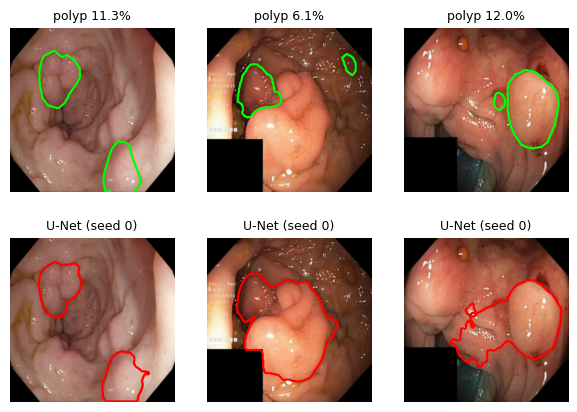

In [3]:
# Look at the misses one by one: images where at least one seed misses a polyp.
missed = []
for i in range(len(names)):
    per_seed = [count_hits(preds[("pretrained", s)][i], Y[i]) for s in (0, 1, 2)]
    # Missed polyps per seed = polyps minus polyps touched.
    lost = [r["polyps"] - r["found_any"] for r in per_seed]
    if max(lost) > 0:
        missed.append((i, lost))
print(len(missed), "images where at least one seed misses a polyp:")
for i, lost in missed:
    print(f"  {names[i]}  polyp share {Y[i].mean():.1%}  missed polyps per seed {lost}")

show = [i for i, _ in missed][:8]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(2.4 * len(show), 5), squeeze=False)
    for k, i in enumerate(show):
        axes[0, k].imshow(X[i]); axes[0, k].contour(Y[i], [0.5], colors="lime")
        axes[0, k].set_title(f"polyp {Y[i].mean():.1%}", fontsize=9)
        axes[1, k].imshow(X[i]); axes[1, k].contour(preds[("pretrained", 0)][i], [0.5], colors="red")
        axes[1, k].set_title("U-Net (seed 0)", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.savefig(R / "C7_missed_polyps.png", dpi=130, bbox_inches="tight"); plt.show()

## Learning-curve gap: training vs. validation vs. test (best epoch, no augmentation)

In [5]:
# Faster: each model loaded once; test predictions reused from above;
# training Dice on a fixed random 200 of the 779 training images (seed 0).
from metrics import mean_scores
torch.set_num_threads(os.cpu_count())
def load(names):
    p = [load_resized(n, 256) for n in names]
    return np.stack([a[0] for a in p]), np.stack([a[1] for a in p])
train_names = read_split("train")
pick = np.random.default_rng(0).choice(len(train_names), 200, replace=False)
Xtr, Ytr = load([train_names[i] for i in sorted(pick)])
Xva, Yva = load(read_split("val"))
gap_rows = ["| U-Net | training (200 of 779) | validation (100) | test (120) | gap training − validation |", "|---|---|---|---|---|"]
for name in ("scratch", "pretrained"):
    tr, va, te = [], [], []
    for seed in (0, 1, 2):
        m = UNet(pretrained=False)
        # Load the weights saved by notebook 03 (no training here).
        m.load_state_dict(torch.load(RUNS / f"{name}_seed{seed}_epochs30.pt", map_location="cpu"))
        m = m.to(device).eval()
        tr.append(mean_scores(predict_probs(m, Xtr, device) > 0.5, Ytr)["dice"])
        va.append(mean_scores(predict_probs(m, Xva, device) > 0.5, Yva)["dice"])
        te.append(mean_scores(preds[(name, seed)], Y)["dice"])
        print(name, seed, f"train {tr[-1]:.3f}  val {va[-1]:.3f}  test {te[-1]:.3f}")
    tr, va, te = np.mean(tr), np.mean(va), np.mean(te)
    gap_rows.append(f"| {name} | {tr:.3f} | {va:.3f} | {te:.3f} | {tr - va:+.3f} |")
gap_table = "\n".join(gap_rows); print(gap_table)

scratch 0 train 0.827  val 0.782  test 0.763
scratch 1 train 0.838  val 0.787  test 0.760
scratch 2 train 0.815  val 0.794  test 0.745
pretrained 0 train 0.914  val 0.867  test 0.856
pretrained 1 train 0.927  val 0.871  test 0.860
pretrained 2 train 0.944  val 0.871  test 0.869
| U-Net | training (200 of 779) | validation (100) | test (120) | gap training − validation |
|---|---|---|---|---|
| scratch | 0.827 | 0.788 | 0.756 | +0.039 |
| pretrained | 0.928 | 0.870 | 0.862 | +0.058 |


## Save

In [6]:
# Save the tables to results/C7_hits.md and zip them for download.
text = f"""# C7 · Not miss one: images and polyps found (120 test images, threshold 0.5)

{table}

A polyp = one connected region of the doctor's mask (≥ 20 pixels at 256 × 256); {n_pol} polyps in {n_img} images.
Touched = any overlap; IoU ≥ 0.5 per image; half covered = ≥ 50 % of that polyp's pixels predicted.
False alarm = a predicted region (≥ 20 pixels) that touches no polyp.
Images where at least one pretrained seed misses a polyp: {len(missed)}.

## Learning-curve gap (Dice, mean of 3 seeds, best validation epoch)

{gap_table}
"""
(R / "C7_hits.md").write_text(text, encoding="utf-8"); print(text)
import zipfile
with zipfile.ZipFile("results_05.zip", "w") as z:
    for f in ("C7_hits.md", "C7_missed_polyps.png"):
        if (R / f).exists(): z.write(R / f)
try:
    from google.colab import files; files.download("results_05.zip")
except ImportError:
    print("results_05.zip written")

# C7 · Not miss one: images and polyps found (120 test images, threshold 0.5)

| Setting | images: polyp touched | images: IoU ≥ 0.5 | polyps found (any overlap) | polyps ≥ half covered | images with a false alarm |
|---|---|---|---|---|---|
| brightness threshold | 104 of 120 (86.7 %) | 15 of 120 (12.5 %) | 108 of 127 (85.0 %) | 79 of 127 (62.2 %) | 16 of 120 (13.3 %) |
| U-Net scratch (3 seeds) | 117.0 ± 1.7 of 120 (97.5 %) | 89.0 ± 1.7 of 120 (74.2 %) | 120.7 ± 2.1 of 127 (95.0 %) | 106.0 ± 2.6 of 127 (83.5 %) | 25.0 ± 8.5 of 120 (20.8 %) |
| U-Net pretrained (3 seeds) | 120.0 ± 0.0 of 120 (100.0 %) | 106.7 ± 1.2 of 120 (88.9 %) | 125.7 ± 0.6 of 127 (99.0 %) | 120.0 ± 2.0 of 127 (94.5 %) | 14.7 ± 8.7 of 120 (12.2 %) |

A polyp = one connected region of the doctor's mask (≥ 20 pixels at 256 × 256); 127 polyps in 120 images.
Touched = any overlap; IoU ≥ 0.5 per image; half covered = ≥ 50 % of that polyp's pixels predicted.
False alarm = a predicted region (≥ 20 pixels) that touches no

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>